# Beach bird detection — CNN

Small network: Conv, BatchNorm, ReLU, then a bird-score map. Peaks on the map become boxes.

`cnn.pt` is the trained model (512px, epoch 5). Running the notebook loads that file and measures it. Training again from random weights is a new run and will not come out at the same score.

**mAP@0.5** means a box counts only when it covers at least half a real bird. The 0.5 is that overlap.

In [1]:
%matplotlib inline
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "dataset" / "beach-bird" / "Beach Bird Detection Dataset v1.0"
WEIGHTS = Path("cnn.pt") if Path("cnn.pt").is_file() else ROOT / "notebooks" / "cnn.pt"
IMG, STRIDE = 512, 4

def load_split(split):
    items = []
    for name in sorted(os.listdir(DATA / "labels" / split)):
        if not name.endswith(".txt"):
            continue
        boxes = []
        for line in open(DATA / "labels" / split / name):
            line = line.strip()
            if not line:
                continue
            _, cx, cy, w, h = [float(v) for v in line.split()]
            cx, cy, w, h = cx * IMG, cy * IMG, w * IMG, h * IMG
            boxes.append([cx - w / 2, cy - h / 2, w, h])
        items.append((str(DATA / "images" / split / name.replace(".txt", ".jpg")),
                      np.array(boxes, np.float32).reshape(-1, 4)))
    return items

val = load_split("val")
print(len(val), "val images,", sum(len(b) for _, b in val), "birds")

291 val images, 1843 birds


## Network

In [2]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, 2, 1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.enc = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128))
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2), nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2), nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
        )
        self.hm, self.wh, self.off = nn.Conv2d(32, 1, 1), nn.Conv2d(32, 2, 1), nn.Conv2d(32, 2, 1)

    def forward(self, x):
        x = self.dec(self.enc(x))
        return self.hm(x), self.wh(x), self.off(x)

model = Net()
ckpt = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["state"])
model.eval()
print("loaded cnn.pt  epoch", ckpt.get("epoch"), " input", ckpt.get("input"))

loaded cnn.pt  epoch 5  input 512


## Validation mAP@0.5

In [3]:
def read_tensor(path):
    im = Image.open(path).convert("RGB").resize((IMG, IMG))
    return torch.from_numpy(np.array(im, np.float32) / 255).permute(2, 0, 1)

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[0] + a[2], b[0] + b[2]), min(a[1] + a[3], b[1] + b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    den = a[2] * a[3] + b[2] * b[3] - inter
    return inter / den if den > 0 else 0

def boxes_from(hm, wh, off, thr=0.02, topk=500):
    score = torch.sigmoid(hm[0])
    keep = (score == F.max_pool2d(score[None, None], 3, 1, 1)[0, 0]) & (score > thr)
    ys, xs = torch.where(keep)
    sc = score[ys, xs]
    if len(sc) > topk:
        sc, idx = sc.topk(topk)
        ys, xs = ys[idx], xs[idx]
    out = []
    for y, x, s in zip(ys, xs, sc):
        bw = math.exp(float(wh[0, y, x])) * IMG
        bh = math.exp(float(wh[1, y, x])) * IMG
        cx = (float(x) + float(off[0, y, x])) * STRIDE
        cy = (float(y) + float(off[1, y, x])) * STRIDE
        out.append(([cx - bw / 2, cy - bh / 2, bw, bh], float(s)))
    return out

def average_precision(records):
    flat, n_gt = [], 0
    for preds, gts in records:
        n_gt += len(gts)
        used = [False] * len(gts)
        for box, s in sorted(preds, key=lambda t: -t[1]):
            best, best_iou = -1, 0.5
            for j, g in enumerate(gts):
                if used[j]:
                    continue
                v = iou(box, g)
                if v >= best_iou:
                    best, best_iou = j, v
            if best >= 0:
                used[best] = True
            flat.append((s, best >= 0))
    flat.sort(key=lambda t: -t[0])
    prec, seen = [], 0
    for i, (_, hit) in enumerate(flat):
        seen += hit
        prec.append(seen / (i + 1))
    for i in range(len(prec) - 2, -1, -1):
        prec[i] = max(prec[i], prec[i + 1])
    return sum(p for (_, hit), p in zip(flat, prec) if hit) / max(n_gt, 1)

records = []
with torch.no_grad():
    for s in range(0, len(val), 4):
        batch = val[s:s + 4]
        hm, wh, off = model(torch.stack([read_tensor(p) for p, _ in batch]))
        for i in range(len(batch)):
            records.append((boxes_from(hm[i], wh[i], off[i]), batch[i][1]))
print(f"val mAP@0.5 = {average_precision(records):.3f}")

val mAP@0.5 = 0.252


Green is the label. Red is the model.

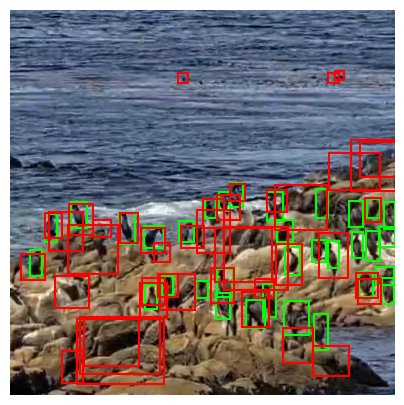

In [4]:
path, gts = val[0]
with torch.no_grad():
    hm, wh, off = model(read_tensor(path)[None])
preds = boxes_from(hm[0], wh[0], off[0])
im = np.array(Image.open(path).convert("RGB"))
plt.figure(figsize=(5, 5))
plt.imshow(im)
ax = plt.gca()
for x, y, w, h in gts:
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="lime", lw=1.5))
for (x, y, w, h), s in preds:
    if s < 0.1:
        continue
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="red", lw=1.5))
plt.axis("off")
plt.show()